# Homework 2

Don't forget to run `pip install -r environment/requirements.txt` before running code in this file.


### Apartment Sales

Let's start by loading in the dataset and previewing the first few rows.

In [35]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


apartment_sales = pd.read_csv("data/Booli_sold.csv")

apartment_sales.head()


,listPrice,rent,livingArea,rooms,published,constructionYear,objectType,booliId,soldDate,soldPrice,...,location.position.latitude,location.position.longitude,location.position.isApproximate,location.region.municipalityName,location.region.countyName,location.distance.ocean,source.name,source.id,source.type,source.url
0,3995000,4467.0,73.0,3.0,2018-10-15 13:33:18,1935.0,Lägenhet,3263989,2018-11-08,3820000,...,59.371033,18.054057,NaN,Stockholm,Stockholms län,260,MOHV,1901865,Broker,http://www.mohv.se/
1,1995000,1773.0,36.0,1.0,2018-10-05 14:29:28,1968.0,Lägenhet,3256231,2018-10-19,2355000,...,59.371242,18.057821,NaN,Stockholm,Stockholms län,218,Notar,1566,Broker,http://www.notar.se/
2,5100000,3839.0,81.0,3.0,2018-09-11 13:44:43,1936.0,Lägenhet,3236660,2018-09-27,6110000,...,59.371617,18.054716,NaN,Stockholm,Stockholms län,186,Historiska Hem AB,65645750,Broker,http://historiskahem.se/
3,5495000,4483.0,107.0,4.0,2018-08-25 02:56:56,1936.0,Lägenhet,3224374,2018-09-06,8050000,...,59.371480,18.053880,NaN,Stockholm,Stockholms län,218,Notar,1566,Broker,http://www.notar.se/
4,1995000,1696.0,29.0,1.0,2018-06-15 17:16:19,1936.0,Lägenhet,3185496,2018-06-18,2400000,...,59.372160,18.053542,True,Stockholm,Stockholms län,166,Mäklarhuset,204,Broker,http://www.maklarhuset.se/


1\. First of all, we want to add a new column, `"ppsqm"` (price per square metre),
which we will calculate by dividing the listing price (`"listPrice"`)
by the living area (`"livingArea"`).

We can then view these quantities for the first few columns of the table
to check that they seem correct.

In [36]:
apartment_sales["ppsqm"] = apartment_sales["listPrice"] / apartment_sales["livingArea"]
apartment_sales[["listPrice", "livingArea", "ppsqm"]].head()

,listPrice,livingArea,ppsqm
0,3995000,73.0,54726.027397
1,1995000,36.0,55416.666667
2,5100000,81.0,62962.962963
3,5495000,107.0,51355.140187
4,1995000,29.0,68793.103448


One apartment has a `"livingArea"` of `NaN`, which leads to it having a `"ppsqm"` of `NaN`,
which seems like a reasonable and desirable outcome. There are no apartments with a `"livingArea"` of 0.
<br>
<br>
---

2\. Now we want to display a few select columns of the 5 apartments with the highest values for `"ppsqm"`.

In [37]:
apartment_sales.sort_values("ppsqm", ascending=False)[["location.address.streetAddress", "livingArea", "listPrice", "ppsqm"]].head()

,location.address.streetAddress,livingArea,listPrice,ppsqm
10,Ekhagsvägen 9,29.0,2295000,79137.931034
50,Ekhagsvägen 8,24.0,1890000,78750.000000
54,Ekhagsvägen 10,23.0,1795000,78043.478261
49,Torphagsvägen 12,47.0,3495000,74361.702128
24,Torphagsvägen 4,35.0,2500000,71428.571429


---

3\. Next, we want to calculate the mean price per square meter.

`DataFrame.mean()` has a `skipna` parameter (that defaults to `True`)
that means `NaN` values are ignored when calculating the mean, which is what we want.

We also want to check that there aren't large outliers that might be disproportionally
impacting the mean. Let's have a look at a box plot to see what the data looks like.

<Axes: >

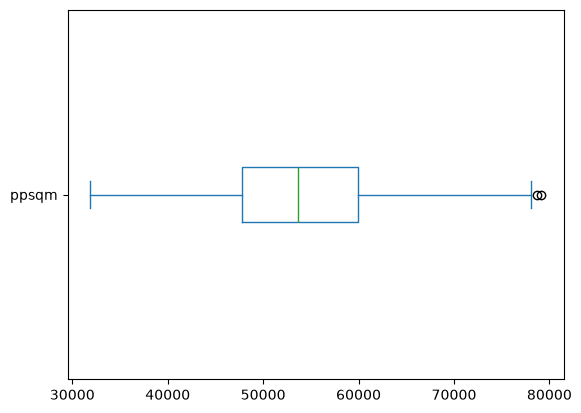

In [38]:
apartment_sales["ppsqm"].plot.box(vert=False)

According to the Pandas documentation, the whiskers of the box plot are
1.5 times the IQR (interquartile range) from the edges of the IQR box.
Values outside of this are commonly considered outliers.

If we look at the box plot, it seems we only have a couple of values
that are considered outliers by this metric, and they are both just
barely outside the whiskers. I do not think it is fair to consider
these to be "true" outliers, and including these points in our mean
calculation will not meaningfully or unreasonably skew the mean.

Thus, we can just calculate the mean of the `"ppsqm"` column using the `.mean()` method.

In [39]:
apartment_sales["ppsqm"].mean()

np.float64(54127.436921333974)

Which gives us a mean of 54127 kr per square metre.
<br>
<br>
---

4\. Finally, let's find an interesting aspect of the data to talk about.
A rather obvious one is that we expect there to be some sort of
positive correlation between living area and list price.

Let's create a scatter plot of living area vs list price to see this visually,
along with a line of best fit. The `seaborn.regplot()` function suits this purpose well.

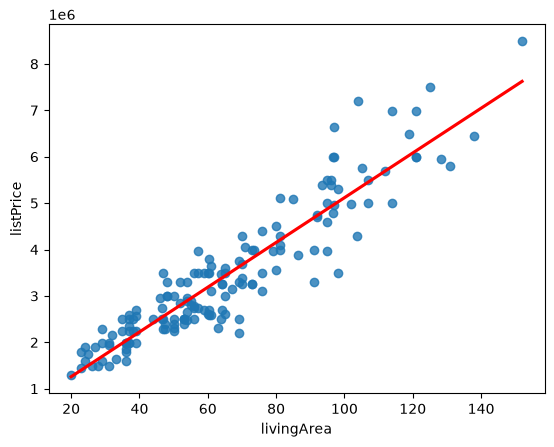

In [45]:
sns.regplot(data=apartment_sales, x="livingArea", y="listPrice", ci=None, line_kws={"color": "red"})
plt.show()

The graph confirms what we expect; that there is a strong correlation
between living area and list price.
Most data points do not vary much from this trend.
We can see the correlation coefficient between these two quantities using the `corr()`
method, so we don't have to rely on our (somewhat subjective)
visual interpretation of the data to draw a conclusion.

In [49]:
apartment_sales["livingArea"].corr(apartment_sales["listPrice"])

np.float64(0.9266695904648657)

This shows us a correlation coefficient of $r \approx 0.9267$,
which indicates a strong correlation between the two quantities.